In [3]:

"""
visualize.py
Matplotlib 静态图

功能：
    1. 柱状图：5 站点 COD 均值对比
    2. 箱线图：各站点 COD 分布
"""


# ---------- 导入库 ----------
import pymysql                          # 连接 MySQL
import pandas as pd                     # 数据处理
import numpy as np                      # 数值计算
import matplotlib.pyplot as plt         # 静态图
from matplotlib import rcParams         # Matplotlib 全局配置
from pyecharts.charts import Line       # pyecharts 折线图
from pyecharts import options as opts   # pyecharts 配置项

# ---------- 全局配置 ----------
# 设置中文字体为黑体，否则图表中文显示为方块
rcParams['font.family'] = 'SimHei'




In [ ]:

# ---------- 加载数据 ----------

from clean_analyze import load_data
df_merge2 = load_data()


输出成功


e:\python文件位置\water-quality-analysis\src\clean_analyze.py:35: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df1 = pd.read_sql('select * from water_quality',conn)
e:\python文件位置\water-quality-analysis\src\clean_analyze.py:36: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df2 = pd.read_sql('select site_id,site_name from site',conn)
e:\python文件位置\water-quality-analysis\src\clean_analyze.py:37: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df3 = pd.read_sql(sql,conn)


输出成功


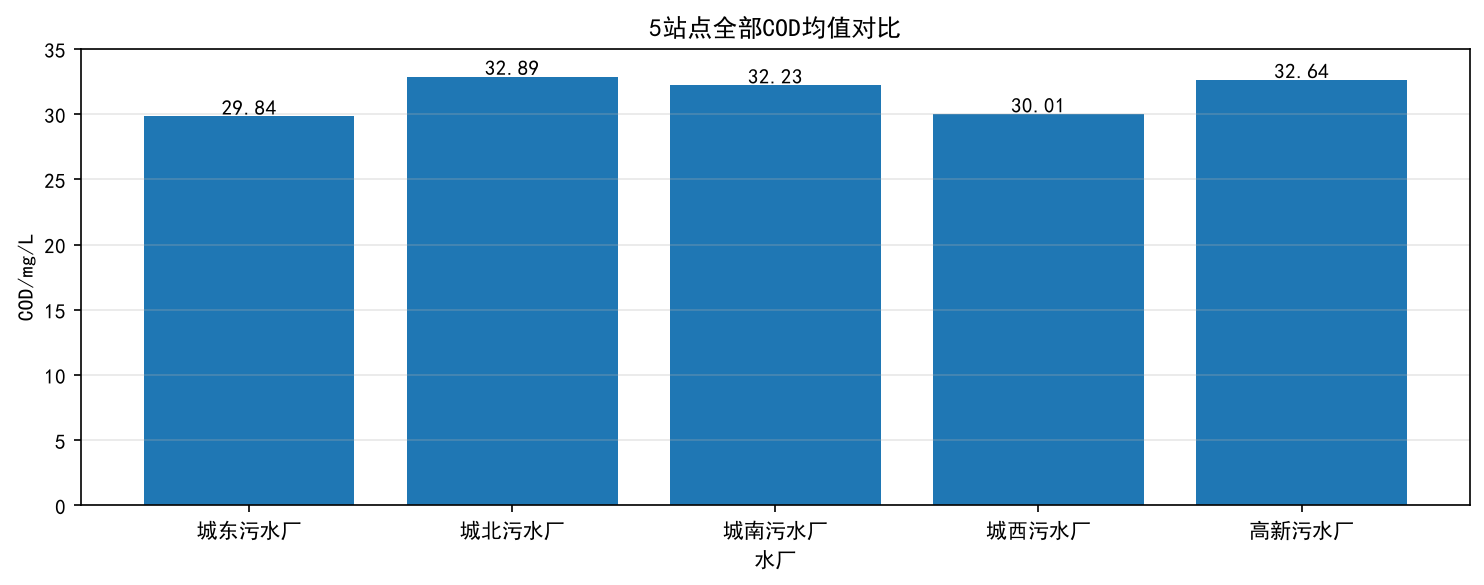

In [ ]:
# ---------- 柱状图 ----------
# 5 站点 COD 均值对比

# Matplotlib  5站点全部cod均值对比

 # 筛选 COD，按站点分组算均值，保留 2 位小数
plt_cod = df_merge2[df_merge2['indictor_name']=='COD'].groupby('site_name')['value'].mean().round(2)

# 创建画布：10×4 英寸，150 DPI
plt.figure(figsize = (10,4),dpi=150)
# 画柱状图：X 轴站点名，Y 轴均值
plt.bar(plt_cod.index,plt_cod.values)
 # 标题和坐标轴标签
plt.title('5站点全部COD均值对比')
# 只显示水平网格线
plt.grid(axis='y',alpha=0.3)

plt.ylim(0,35)
plt.xlabel('水厂')
plt.ylabel('COD/mg/L')
# 在每根柱子顶部显示数值
for x,y in enumerate(plt_cod.values):
    plt.text(x,y+0.1,f"{y}",ha='center')


plt.tight_layout()
# 保存图片
plt.savefig(fname='output/cod_bar.png')

print('输出成功')
plt.show()


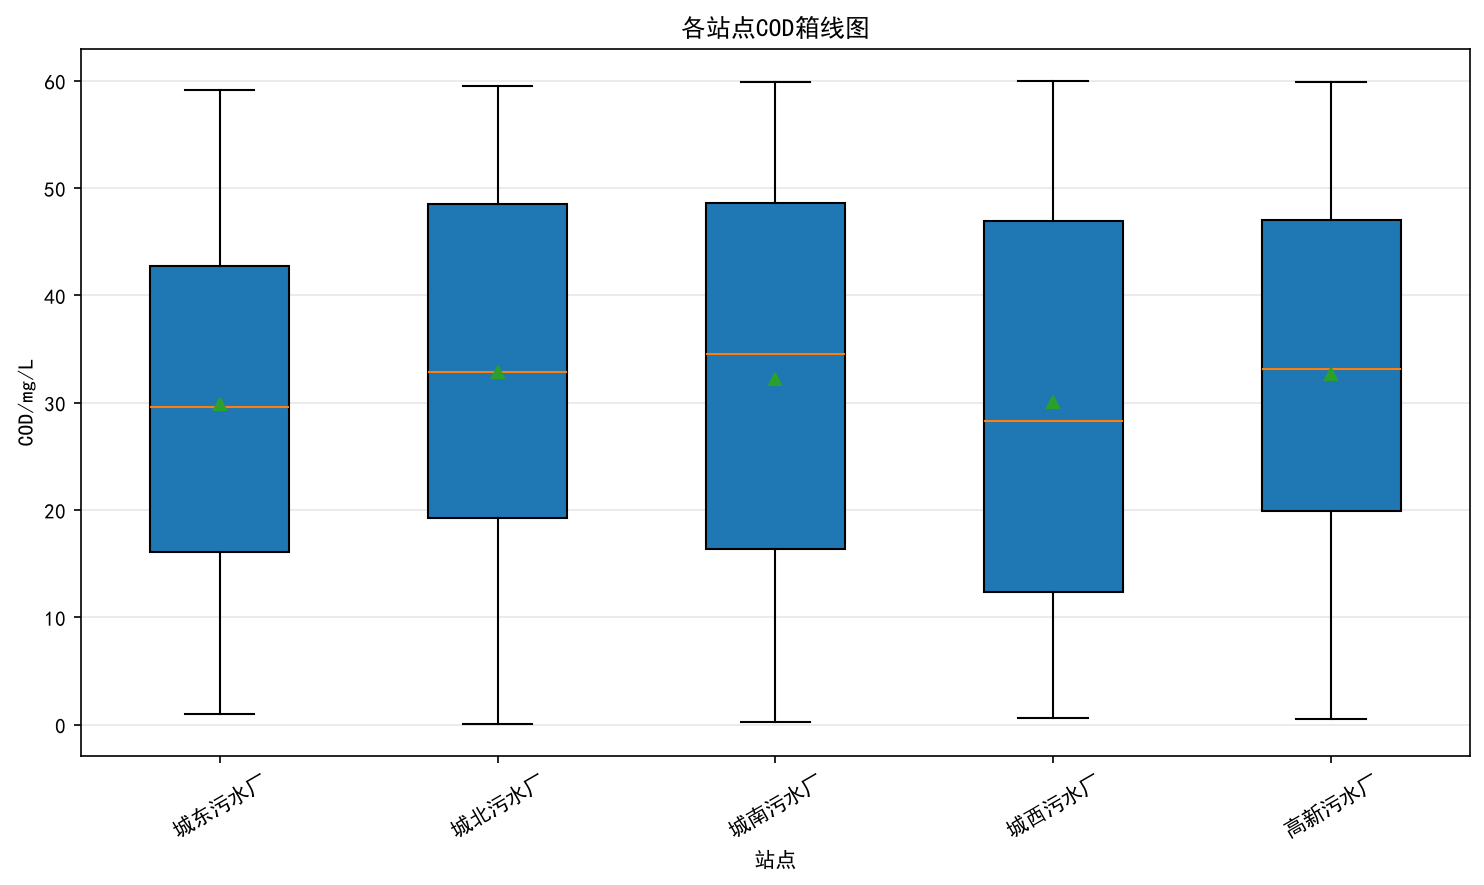

In [ ]:
# ----------箱线图 ----------
# 各站点 COD 分布

#Matplotlib  各站点COD箱线图箱线图  
# 定义函数，参数 path 是 DataFrame。
def cod_boxplot(path):
    '''
    画各站点 COD 分布箱线图。
    箱线图能看出：
        1. 中位数：各站点 COD 的典型值
        2. 箱体长度：数据离散程度，越长波动越大
        3. 异常值：超出上下须的点，可能是异常数据'''
    data_list = []
    site_names = []
    # 只留 COD 行
    path_value_sitename = path[path['indictor_name'] == 'COD' ]
    # 按站点分组，把每组的值和站点名分别存进列表
    for i in path_value_sitename.groupby('site_name'):
        data_list.append(i[1]['value'].tolist())
        site_names.append(i[0])
    plt.figure(figsize=(10,6),dpi=150)
    # 画箱线图
    # tick_labels    : 每个箱体的标签
    # showmeans      : 显示均值点
    # patch_artist   : 箱体填充颜色
    # showfliers     : 显示异常值点
    plt.boxplot(data_list,tick_labels=site_names,showmeans=True,patch_artist=True,showfliers=True)
    plt.title("各站点COD箱线图")
    plt.ylabel("COD/mg/L")
    plt.xlabel("站点")
    plt.xticks(rotation=30) 
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()

    # 保存图片
    save_path = 'output/test_cod_bar.png'
    plt.savefig(save_path)
    plt.show()
       
    
cod_boxplot(df_merge2)